In [1]:
# Memanggil library yang dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Library untuk persiapan model
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

print("Semua library berhasil dipanggil!")

Semua library berhasil dipanggil!


In [2]:
# Mengunggah dataset dari komputer
from google.colab import files

uploaded = files.upload()

Saving case2_customer_churn.csv to case2_customer_churn.csv


In [3]:
# Membaca dataset
df_mentah = pd.read_csv('case2_customer_churn.csv')

# Menampilkan 5 data pertama
df_mentah.head()

,customer_id,lama_berlangganan_bulan,jenis_kontrak,tagihan_bulanan_idr,total_tagihan_idr,layanan_internet,jumlah_layanan_aktif,dukungan_teknis,jumlah_komplain,hari_sejak_interaksi_terakhir,metode_pembayaran,status_pelanggan
0,TEL000001,41.0,Dua Tahun,140611.0,5860742.0,DSL,8.0,Tidak,11.0,331.0,Transfer Bank,Aktif
1,TEL000002,5.0,Tahunan,363720.0,1742224.0,Tidak Ada,7.0,Ya,12.0,156.0,Autodebet,Aktif
2,TEL000003,56.0,Bulanan,208727.0,11685438.0,DSL,6.0,Tidak,9.0,105.0,Transfer Bank,Churn
3,TEL000004,NaN,Dua Tahun,135607.0,5599065.0,Fiber Optik,2.0,Ya,12.0,100.0,Kartu Kredit,Churn
4,TEL000005,7.0,Bulanan,71099.0,427199.0,Tidak Ada,1.0,Tidak,1.0,19.0,QRIS,Churn


Penjelasan:

pd.read_csv() digunakan untuk membaca file CSV menjadi tabel DataFrame.

head() digunakan untuk menampilkan lima baris pertama dari dataset.

### **Melihat Informasi Dataset**

In [4]:
# Melihat ukuran dataset
print("Ukuran Dataset:", df_mentah.shape)

# Melihat informasi kolom
df_mentah.info()

# Melihat statistik data numerik
df_mentah.describe()

Ukuran Dataset: (5000, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   customer_id                    5000 non-null   object 
 1   lama_berlangganan_bulan        4900 non-null   float64
 2   jenis_kontrak                  4853 non-null   object 
 3   tagihan_bulanan_idr            4857 non-null   float64
 4   total_tagihan_idr              4763 non-null   float64
 5   layanan_internet               4844 non-null   object 
 6   jumlah_layanan_aktif           4819 non-null   float64
 7   dukungan_teknis                4852 non-null   object 
 8   jumlah_komplain                4836 non-null   float64
 9   hari_sejak_interaksi_terakhir  4797 non-null   float64
 10  metode_pembayaran              4841 non-null   object 
 11  status_pelanggan               5000 non-null   object 
dtypes: float64(6), object

,lama_berlangganan_bulan,tagihan_bulanan_idr,total_tagihan_idr,jumlah_layanan_aktif,jumlah_komplain,hari_sejak_interaksi_terakhir
count,4900.000000,4857.000000,4.763000e+03,4819.000000,4836.000000,4797.000000
mean,36.624082,273390.505250,9.962093e+06,4.528740,7.482837,182.542631
std,21.056159,130685.216371,7.951489e+06,2.282951,4.672071,105.117812
min,1.000000,50245.000000,0.000000e+00,1.000000,0.000000,0.000000
25%,18.000000,160098.000000,3.503040e+06,3.000000,3.000000,93.000000
50%,36.000000,272473.000000,7.873608e+06,5.000000,8.000000,183.000000
75%,55.000000,388440.000000,1.464650e+07,7.000000,12.000000,272.000000
max,72.000000,499966.000000,3.561553e+07,8.000000,15.000000,365.000000


Penjelasan:
- shape: mengetahui jumlah baris dan kolom.
- info(): melihat nama kolom dan tipe datanya.
- describe(): melihat nilai rata-rata, minimum, maksimum, dan statistik lainnya.

### **Pemeriksaan Kualitas Data**
Pada tahap ini kita akan mencari:
1. Data duplikat.
2. Missing value (data kosong).
3. Outlier (nilai yang terlalu jauh).
4. Tipe data.

In [5]:
# Melihat jumlah data kosong setiap kolom
print("Missing Value:")
print(df_mentah.isnull().sum())

# Melihat jumlah data duplikat
print("\nJumlah Duplikat:")
print(df_mentah.duplicated().sum())

# Melihat tipe data
print("\nTipe Data:")
print(df_mentah.dtypes)

Missing Value:
customer_id                        0
lama_berlangganan_bulan          100
jenis_kontrak                    147
tagihan_bulanan_idr              143
total_tagihan_idr                237
layanan_internet                 156
jumlah_layanan_aktif             181
dukungan_teknis                  148
jumlah_komplain                  164
hari_sejak_interaksi_terakhir    203
metode_pembayaran                159
status_pelanggan                   0
dtype: int64

Jumlah Duplikat:
0

Tipe Data:
customer_id                       object
lama_berlangganan_bulan          float64
jenis_kontrak                     object
tagihan_bulanan_idr              float64
total_tagihan_idr                float64
layanan_internet                  object
jumlah_layanan_aktif             float64
dukungan_teknis                   object
jumlah_komplain                  float64
hari_sejak_interaksi_terakhir    float64
metode_pembayaran                 object
status_pelanggan                  object
dtyp

### **Membuat Fungsi Audit Kualitas Data**

In [11]:
def cek_kualitas(d, kolom_num, kolom_grup, kunci):

    # Menghitung batas outlier menggunakan IQR
    g = d.groupby(kolom_grup, observed=True)[kolom_num]

    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))

    iqr = q3 - q1

    # Mendeteksi outlier
    outlier = (
        (d[kolom_num] < q1 - 1.5 * iqr) |
        (d[kolom_num] > q3 + 1.5 * iqr)
    )

    return pd.Series({
        'n_baris': len(d),
        'n_duplikat': d.duplicated(subset=kunci).sum(),
        'n_missing': d.isnull().sum().sum(),
        'n_outlier': outlier.sum().sum()
    })


# Menampilkan hasil audit awal
audit_awal = cek_kualitas(
    df_mentah, kolom_num, kolom_grup, kunci
)

print(audit_awal)

n_baris       5000
n_duplikat       0
n_missing     1638
n_outlier       55
dtype: int64


Penjelasan:

Fungsi ini digunakan untuk mengetahui kondisi awal dataset.
- n_baris: jumlah baris data.
- n_duplikat: jumlah data pelanggan yang duplikat.
- n_missing: jumlah data kosong.
- n_outlier: jumlah nilai yang terdeteksi sebagai outlier

### **Membersihkan Dataset**
 urutan pembersihan adalah:
1. Menghapus duplikat.
2. Menangani missing value.
3. Menangani outlier.
4. Memperbaiki tipe data.

In [13]:
# Membuat salinan dataset mentah
df_bersih = df_mentah.copy()

# 1. Menghapus data duplikat
df_bersih = df_bersih.drop_duplicates(
    subset='customer_id'
)

# 2. Memperbaiki nilai kategori yang tidak konsisten
df_bersih['jenis_kontrak'] = (
    df_bersih['jenis_kontrak']
    .replace('T@hun@n', 'Tahunan')
)

# Mengisi data kosong numerik dengan median
for kolom in kolom_num:
    df_bersih[kolom] = df_bersih[kolom].fillna(
        df_bersih[kolom].median()
    )

# Mengisi data kosong kategori dengan modus
kolom_kategori = df_bersih.select_dtypes(
    include='object'
).columns.tolist()

for kolom in kolom_kategori:
    if df_bersih[kolom].isnull().any():
        df_bersih[kolom] = df_bersih[kolom].fillna(
            df_bersih[kolom].mode()[0]
        )

print("Missing value berhasil ditangani!")

Missing value berhasil ditangani!


Penjelasan:
- copy(): membuat salinan dataset agar data asli tidak berubah.
- drop_duplicates(): menghapus pelanggan yang tercatat lebih dari sekali.
- median(): mengisi data numerik kosong menggunakan nilai tengah.
- mode(): mengisi data kategori kosong menggunakan nilai yang paling sering muncul.

Mengapa menggunakan median dan modus? Karena median cukup tahan terhadap nilai ekstrem, sedangkan modus cocok untuk data berbentuk kategori.

In [14]:
# 3. Menangani outlier menggunakan metode IQR

for kolom in kolom_num:

    q1 = df_bersih.groupby(
        kolom_grup, observed=True
    )[kolom].transform(lambda s: s.quantile(0.25))

    q3 = df_bersih.groupby(
        kolom_grup, observed=True
    )[kolom].transform(lambda s: s.quantile(0.75))

    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    df_bersih[kolom] = df_bersih[kolom].clip(
        lower=batas_bawah,
        upper=batas_atas
    )

print("Outlier berhasil ditangani!")

Outlier berhasil ditangani!


In [15]:
# 4. Memperbaiki tipe data numerik
for kolom in kolom_num:
    df_bersih[kolom] = pd.to_numeric(
        df_bersih[kolom], errors='coerce'
    )

# Memastikan ID dan target berbentuk kategori
df_bersih['customer_id'] = (
    df_bersih['customer_id'].astype(str)
)

df_bersih['status_pelanggan'] = (
    df_bersih['status_pelanggan'].astype(str)
)

print("Tipe data berhasil diperiksa!")
df_bersih.info()

Tipe data berhasil diperiksa!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   customer_id                    5000 non-null   object 
 1   lama_berlangganan_bulan        5000 non-null   float64
 2   jenis_kontrak                  5000 non-null   object 
 3   tagihan_bulanan_idr            5000 non-null   float64
 4   total_tagihan_idr              5000 non-null   float64
 5   layanan_internet               5000 non-null   object 
 6   jumlah_layanan_aktif           5000 non-null   float64
 7   dukungan_teknis                5000 non-null   object 
 8   jumlah_komplain                5000 non-null   float64
 9   hari_sejak_interaksi_terakhir  5000 non-null   float64
 10  metode_pembayaran              5000 non-null   object 
 11  status_pelanggan               5000 non-null   object 
dtypes: float64(6), obj

### **Membandingkan Kualitas Data**

In [17]:
# Membuat laporan kualitas data
laporan = pd.DataFrame({
    'sebelum': cek_kualitas(
        df_mentah, kolom_num, kolom_grup, kunci
    ),
    'sesudah': cek_kualitas(
        df_bersih, kolom_num, kolom_grup, kunci
    )
})

laporan

,sebelum,sesudah
n_baris,5000,5000
n_duplikat,0,0
n_missing,1638,0
n_outlier,lama_berlangganan_bulan 0 tagihan_bu...,lama_berlangganan_bulan 0 tagihan_bul...


Penjelasan:

Tabel ini memperlihatkan apakah proses pembersihan berhasil.


- Jumlah missing value berkurang.
- Jumlah duplikat berkurang.
- Jumlah outlier  berkurang.
- Jumlah baris dapat berkurang jika ditemukan duplikat.

In [19]:
laporan.to_csv(
    'laporan_kualitas.csv',
    index=True
)

### **Analisis Data**
1. Analisis pertama: jumlah pelanggan aktif dan churn.

status_pelanggan
Aktif    2819
Churn    2181
Name: count, dtype: int64


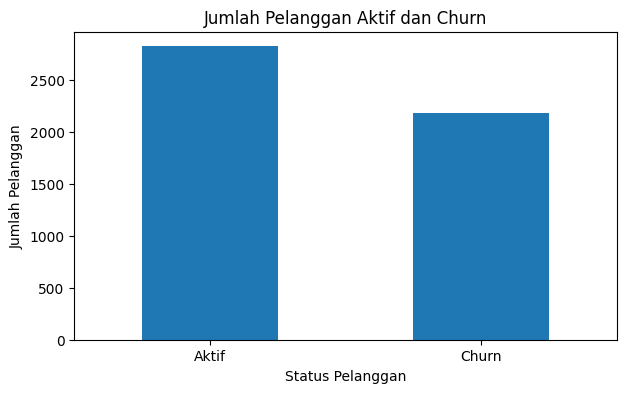

In [20]:
# Menghitung jumlah status pelanggan
status = df_bersih['status_pelanggan'].value_counts()

print(status)

# Membuat grafik
status.plot(kind='bar', figsize=(7, 4))

plt.title('Jumlah Pelanggan Aktif dan Churn')
plt.xlabel('Status Pelanggan')
plt.ylabel('Jumlah Pelanggan')
plt.xticks(rotation=0)
plt.show()

Penjelasan:

Grafik ini menunjukkan perbandingan pelanggan yang masih aktif dengan pelanggan yang sudah berhenti berlangganan.

2. Analisis kedua: churn berdasarkan jenis kontrak.

status_pelanggan  Aktif  Churn
jenis_kontrak                 
BULANAN               3      3
Bul@n@n               2      5
Bulanan             652    968
DUA TAHUN            11      0
Du@ T@hun             7      2
Dua Tahun          1194    576
TAHUNAN               5      0
Tahunan             932    617
bulanan               6      7
dua tahun             1      0
tahunan               6      3


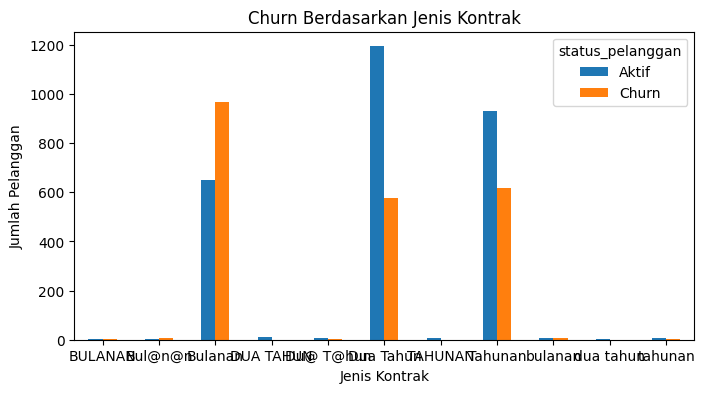

In [21]:
# Mengelompokkan pelanggan berdasarkan kontrak
analisis_kontrak = pd.crosstab(
    df_bersih['jenis_kontrak'],
    df_bersih['status_pelanggan']
)

print(analisis_kontrak)

analisis_kontrak.plot(
    kind='bar',
    figsize=(8, 4)
)

plt.title('Churn Berdasarkan Jenis Kontrak')
plt.xlabel('Jenis Kontrak')
plt.ylabel('Jumlah Pelanggan')
plt.xticks(rotation=0)
plt.show()

3. Analisis ketiga: rata-rata tagihan berdasarkan status pelanggan.

status_pelanggan
Aktif    271059.923022
Churn    276342.686841
Name: tagihan_bulanan_idr, dtype: float64


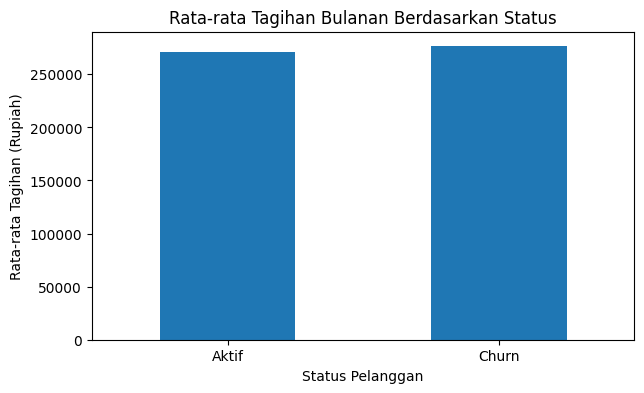

In [22]:
analisis_tagihan = df_bersih.groupby(
    'status_pelanggan'
)['tagihan_bulanan_idr'].mean()

print(analisis_tagihan)

analisis_tagihan.plot(
    kind='bar',
    figsize=(7, 4)
)

plt.title('Rata-rata Tagihan Bulanan Berdasarkan Status')
plt.xlabel('Status Pelanggan')
plt.ylabel('Rata-rata Tagihan (Rupiah)')
plt.xticks(rotation=0)
plt.show()

**Menuliskan 3 Temuan Analisis**


*   **Temuan status pelanggan:** berdasarkan grafik pertama, terdapat 2819
pelanggan aktif dan 2181 pelanggan churn. Perusahaan perlu memperhatikan jumlah pelanggan yang berhenti.
*   **Temuan jenis kontrak:** jenis kontrak Bulanan memiliki persentase churn tertinggi. Perusahaan dapat mengevaluasi layanan dan strategi mempertahankan pelanggan pada kelompok tersebut.
*   **Temuan tagihan:** rata-rata tagihan pelanggan churn adalah 271059.923022 sedangkan pelanggan aktif adalah 276342.686841 . Perusahaan dapat mengevaluasi kesesuaian harga dengan layanan.


### **Persiapan Data untuk Machine Learning**
Tahap ini bertujuan menyiapkan dataset agar bisa digunakan oleh algoritma machine learning.

Kita akan menggunakan:
- train_test_split: membagi data menjadi data latihan dan pengujian.
- ColumnTransformer: memproses kolom numerik dan kategori.
- StandardScaler: menyamakan skala data numerik.
- OneHotEncoder: mengubah data kategori menjadi bentuk numerik.

**Langkah pertama: menentukan fitur dan target.**

In [24]:
# Menentukan target yang akan diprediksi
X = df_bersih.drop(
    columns=['status_pelanggan', 'customer_id']
)

y = df_bersih['status_pelanggan']

print("Fitur:")
print(X.head())

print("\nTarget:")
print(y.head())

Fitur:
   lama_berlangganan_bulan jenis_kontrak  tagihan_bulanan_idr  \
0                     41.0     Dua Tahun             140611.0   
1                      5.0       Tahunan             363720.0   
2                     56.0       Bulanan             208727.0   
3                     36.0     Dua Tahun             135607.0   
4                      7.0       Bulanan              71099.0   

   total_tagihan_idr layanan_internet  jumlah_layanan_aktif dukungan_teknis  \
0          5860742.0              DSL                   8.0           Tidak   
1          1742224.0        Tidak Ada                   7.0              Ya   
2         11685438.0              DSL                   6.0           Tidak   
3          5599065.0      Fiber Optik                   2.0              Ya   
4           427199.0        Tidak Ada                   1.0           Tidak   

   jumlah_komplain  hari_sejak_interaksi_terakhir metode_pembayaran  
0             11.0                          331.0     Tra

Penjelasan:
- X adalah data yang digunakan untuk memprediksi.
- y adalah hasil yang ingin diprediksi, yaitu status pelanggan.
- customer_id tidak digunakan karena hanya merupakan identitas pelanggan.

**Langkah kedua: membagi data**

In [25]:
# Membagi dataset menjadi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah Data Training:", len(X_train))
print("Jumlah Data Testing:", len(X_test))

Jumlah Data Training: 4000
Jumlah Data Testing: 1000


Penjelasan:
- 80% data digunakan untuk latihan.
- 20% data digunakan untuk pengujian.

**Langkah ketiga: preprocessing menggunakan ColumnTransformer.**

In [26]:
# Memisahkan kolom numerik dan kategori
kolom_numerik = X_train.select_dtypes(
    include=np.number
).columns.tolist()

kolom_kategori = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Proses data numerik
proses_numerik = Pipeline([
    ('scaler', StandardScaler())
])

# Proses data kategori
proses_kategori = Pipeline([
    ('encoder', OneHotEncoder(
        handle_unknown='ignore'
    ))
])

# Menggabungkan proses preprocessing
preprocessor = ColumnTransformer([
    ('numerik', proses_numerik, kolom_numerik),
    ('kategori', proses_kategori, kolom_kategori)
])

# Fit hanya pada data training
X_train_proses = preprocessor.fit_transform(X_train)

# Data testing hanya ditransformasi
X_test_proses = preprocessor.transform(X_test)

print("Preprocessing berhasil!")
print("Ukuran data training:", X_train_proses.shape)
print("Ukuran data testing:", X_test_proses.shape)

Preprocessing berhasil!
Ukuran data training: (4000, 26)
Ukuran data testing: (1000, 26)


Penjelasan:

ColumnTransformer digunakan untuk mengolah data berdasarkan jenis kolomnya.

In [27]:
import os

# Membuat folder output
os.makedirs('output', exist_ok=True)
os.makedirs('data', exist_ok=True)

# Menyimpan dataset bersih
df_bersih.to_csv(
    'output/data_bersih.csv',
    index=False
)

# Membuat kamus data
kamus_data = pd.DataFrame({
    'kolom': df_bersih.columns,
    'tipe_data': df_bersih.dtypes.astype(str).values,
    'n_missing': df_bersih.isnull().sum().values,
    'n_unik': df_bersih.nunique().values
})

# Menyimpan kamus data
kamus_data.to_csv(
    'output/kamus_data.csv',
    index=False
)

# Menyimpan laporan kualitas
laporan.to_csv(
    'laporan_kualitas.csv'
)

print("Semua output berhasil disimpan!")

Semua output berhasil disimpan!


In [29]:
import shutil

shutil.copy(
    'case2_customer_churn.csv',
    'data/case2_customer_churn.csv'
)

print("Dataset asli berhasil dimasukkan ke folder data!")

Dataset asli berhasil dimasukkan ke folder data!


In [31]:
files.download('output/data_bersih.csv')
files.download('output/kamus_data.csv')
files.download('laporan_kualitas.csv')
files.download('data/case2_customer_churn.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>